# **Importing the Libraries**

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Uploading and Reading the File

In [11]:
uploaded = files.upload()
df = pd.read_csv(next(iter(uploaded.keys())))

# Remove accidental spaces from column names
df.columns = df.columns.str.strip()

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

Saving Dataset.csv to Dataset.csv
Dataset shape: (24, 18)
Columns: ['S.NO', 'NAME OF RESERVOIR', 'STATE', 'BENEFITS IRR (TH. HA)', 'HYDEL IN MW', 'FRL (MTS.)', 'LIVE CAP. AT FRL (BCM)', 'DATE', 'THIS SEASON LEVEL (MTS)', 'THIS YEAR LIVE STORAGE (BCM)', 'THIS YR STORAGE AS % OF LIVE CAP', 'LAST SEASON LEVEL (MTS)', 'LAST YEAR LIVE STORAGE (BCM)', 'LAST YR STORAGE AS % OF LIVE CAP', 'Normal Storage (BCM)', 'Normal Storage as % of Live Cap. At FRL', '% OF THIS YR TO LAST YEARS STORAGE', '% OF THIS YR TO NORMAL STORAGE']


# Selecting feature and Target

In [12]:
target_column = "THIS YEAR LIVE STORAGE (BCM)"

feature_columns = [
    "LIVE CAP. AT FRL (BCM)",
    "THIS SEASON LEVEL (MTS)",
    "LAST YEAR LIVE STORAGE (BCM)",
    "Normal Storage (BCM)"
]

# Keep the required columns
data = df[feature_columns + [target_column]].copy()

# Convert columns to numeric values
for col in feature_columns + [target_column]:
    data[col] = pd.to_numeric(data[col], errors="coerce")

# Remove rows where the target is missing
data = data.dropna(subset=[target_column]).reset_index(drop=True)

X = data[feature_columns]
y = data[target_column]


# SPLIT DATA INTO TRAINING AND TESTING SETS

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("\nTraining rows:", len(X_train))
print("Testing rows:", len(X_test))



Training rows: 19
Testing rows: 5


# DEFINE REGRESSION MODELS

In [14]:
models = {
    "Linear Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        LinearRegression()
    ),

    "Polynomial Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        PolynomialFeatures(degree=2, include_bias=False),
        LinearRegression()
    ),

    "Ridge Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        Ridge(alpha=1.0)
    ),

    "KNN Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=5)
    )
}

#  TRAIN, PREDICT, AND EVALUATE

In [15]:
results = []
predictions = pd.DataFrame({
    "Actual_Storage_BCM": y_test.to_numpy()
}, index=y_test.index)

for name, model in models.items():

    # Train the model
    model.fit(X_train, y_train)

    # Predict test-set values
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "RMSE": rmse,
        "MAE": mae,
        "R2": r2
    })

    predictions[name + "_Prediction"] = y_pred

    print(f"\n--- {name} ---")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAE:  {mae:.4f}")
    print(f"R2:   {r2:.4f}")


--- Linear Regression ---
RMSE: 0.0702
MAE:  0.0568
R2:   0.9608

--- Polynomial Regression ---
RMSE: 0.6912
MAE:  0.4712
R2:   -2.8043

--- Ridge Regression ---
RMSE: 0.0836
MAE:  0.0727
R2:   0.9444

--- KNN Regression ---
RMSE: 0.2840
MAE:  0.2259
R2:   0.3579


#  CREATE FINAL CSV FILES

In [16]:
results_df = pd.DataFrame(results)

# Sort models by RMSE (lower is better)
results_df = results_df.sort_values(
    by="RMSE",
    ascending=True
)

results_df.to_csv("model_comparison.csv", index=False)

predictions = predictions.sort_index()
predictions.to_csv("model_predictions.csv", index_label="Original_Row_Index")



# Display Result

In [17]:
print("\nMODEL COMPARISON")
display(results_df.round(4))

print("\nMODEL PREDICTIONS")
display(predictions.head(10).round(4))


MODEL COMPARISON


,Model,RMSE,MAE,R2
0,Linear Regression,0.0702,0.0568,0.9608
2,Ridge Regression,0.0836,0.0727,0.9444
3,KNN Regression,0.2840,0.2259,0.3579
1,Polynomial Regression,0.6912,0.4712,-2.8043



MODEL PREDICTIONS


,Actual_Storage_BCM,Linear Regression_Prediction,Polynomial Regression_Prediction,Ridge Regression_Prediction,KNN Regression_Prediction
0,0.003,0.0274,0.0918,0.0391,0.1850
8,0.287,0.3114,0.5893,0.3252,0.1850
11,0.032,0.1536,0.1943,0.1587,0.0886
16,0.864,0.8406,0.5276,0.8209,0.3192
18,0.729,0.8190,-0.7373,0.8483,0.4848


# Download Result

In [18]:
files.download("model_comparison.csv")
files.download("model_predictions.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Model Performance Comparison Graph
This graph compares RMSE, MAE, and R² for all four models.

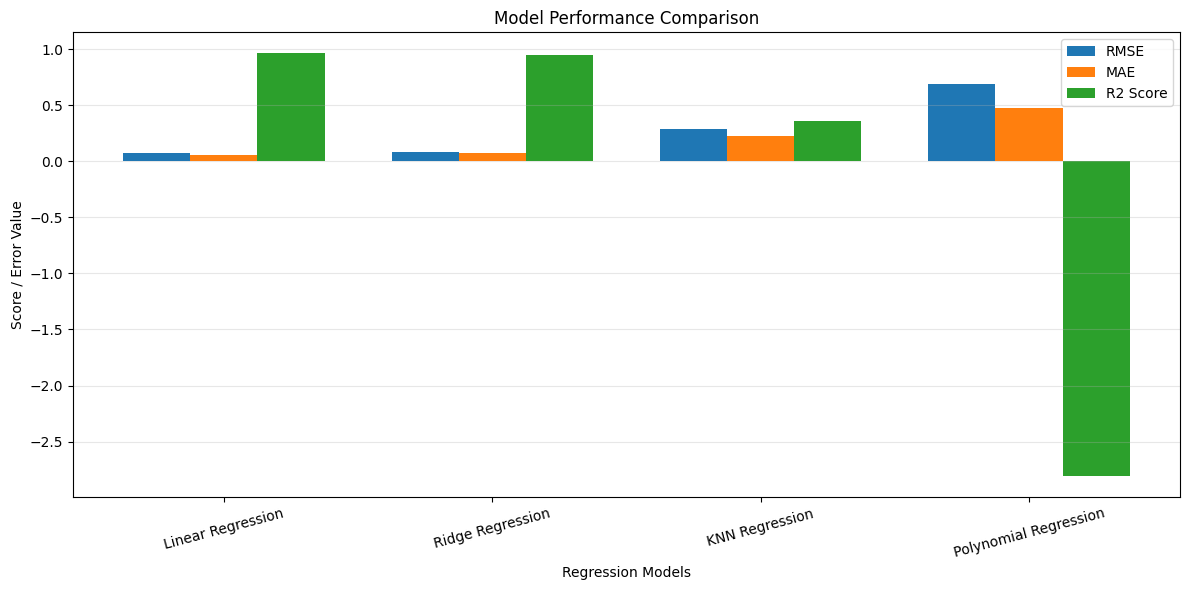

In [19]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(12, 6))

x = np.arange(len(results_df))
width = 0.25

plt.bar(x - width, results_df["RMSE"],
        width, label="RMSE")

plt.bar(x, results_df["MAE"],
        width, label="MAE")

plt.bar(x + width, results_df["R2"],
        width, label="R2 Score")

plt.xlabel("Regression Models")
plt.ylabel("Score / Error Value")
plt.title("Model Performance Comparison")

plt.xticks(x, results_df["Model"], rotation=15)
plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("model_performance_comparison.png", dpi=300)
plt.show()

# Actual vs Predicted Values Graph
This graph compares the actual reservoir storage with the predictions from all four models.

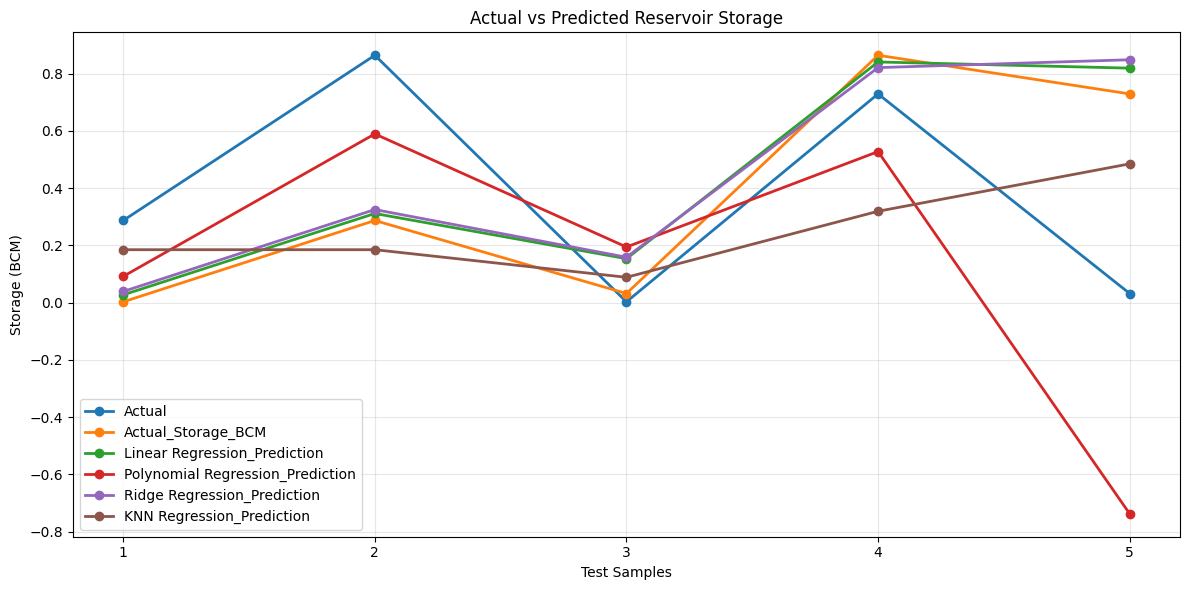

In [20]:
plt.figure(figsize=(12, 6))

plt.plot(
    range(1, len(y_test) + 1),
    y_test.values,
    marker="o",
    linewidth=2,
    label="Actual"
)

for name, y_pred in predictions.items():
    plt.plot(
        range(1, len(y_pred) + 1),
        y_pred,
        marker="o",
        linewidth=2,
        label=name
    )

plt.xlabel("Test Samples")
plt.ylabel("Storage (BCM)")
plt.title("Actual vs Predicted Reservoir Storage")

plt.xticks(range(1, len(y_test) + 1))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("actual_vs_predicted.png", dpi=300)
plt.show()

# Actual vs Predicted Scatter Plot (Linear Regression)
This additional graph shows how closely Linear Regression predictions follow actual values.

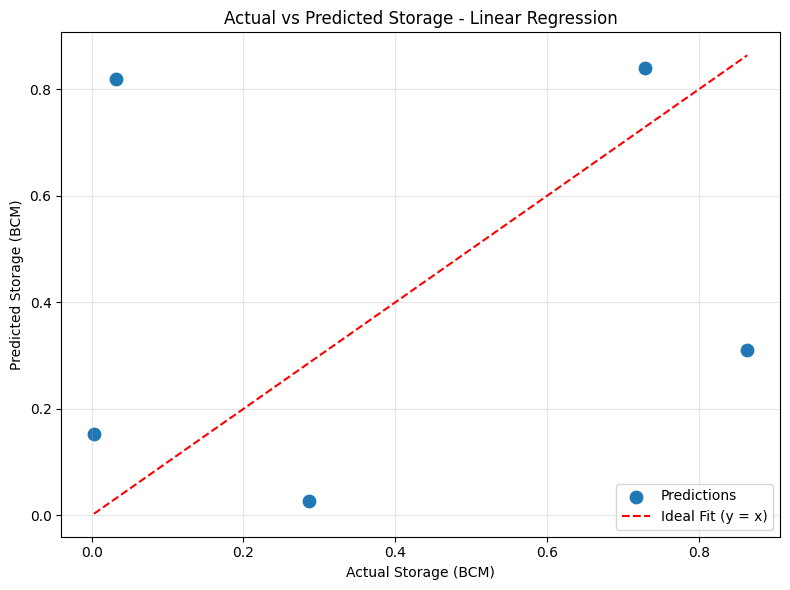

In [22]:
linear_pred = predictions["Linear Regression_Prediction"]

plt.figure(figsize=(8, 6))

plt.scatter(y_test, linear_pred, s=80, label="Predictions")

# Ideal prediction line
minimum = min(y_test.min(), linear_pred.min())
maximum = max(y_test.max(), linear_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    "r--",
    label="Ideal Fit (y = x)"
)

plt.xlabel("Actual Storage (BCM)")
plt.ylabel("Predicted Storage (BCM)")
plt.title("Actual vs Predicted Storage - Linear Regression")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("linear_regression_scatter.png", dpi=300)
plt.show()

# Downloading all graphs

In [23]:
from google.colab import files

files.download("model_performance_comparison.png")
files.download("actual_vs_predicted.png")
files.download("linear_regression_scatter.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>